
 # RFM-CLV
 
 ## Let´s create a model based on two parts. 
    -  First, develop a RFM model which serves as a based for the second
    -  CLV model using lifetimes library


    The RFM is a method used for analyzing customer value and segmenting customers which is commonly used in database marketing and direct marketing. It has received particular attention in the retail and professional services industries. [Wikipedia]

    RFM stands for the three dimensions:

    Recency – How recently did the customer purchase?
    Frequency – How often do they purchase?
    Monetary Value – How much do they spend?


    Customer Lifetime Value is a metric that estimates the total revenue that a business can expect from a single customer account throughout their engagement. CLV is significant as it helps businesses to understand the value of acquiring and retaining customers. It allows for strategic budgeting and helps in optimizing marketing spend.[https://pyquesthub.com/]


## 1. Libraries
 

In [38]:
# Cargamos las librerias
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import plotly.express as px
from sklearn.cluster import KMeans
#from sklearn_extra.cluster import KMedoids
from sklearn.preprocessing import StandardScaler

import datetime
from datetime import timedelta
from datetime import date

# import squarify

from lifetimes.plotting import *
from lifetimes.utils import *
from lifetimes import BetaGeoFitter
from lifetimes import GammaGammaFitter

from scipy.stats import gamma, beta

#from sklearn_extra.cluster import KMedoids
import warnings
warnings.filterwarnings('ignore')

In [22]:
#pip install lifetimes


## 2. Data Loading and data preparation 

Data is already clean, as the point of this notebook is to focus on the generacion of the RFM and CLV

In [25]:
# Loading data

df = pd.read_csv('marketing_campaign.csv',header=0,sep=';')
pd.set_option('display.max_columns', None) # para ver todas las columnas
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


In [27]:
# count totals (compras, interacciones, etc.)
total_clientes = df['ID'].count()

# Numer of unique customers
clientes_unicos = df['ID'].nunique()

print(f"Total de registros de clientes: {total_clientes}")
print(f"Número de clientes distintos: {clientes_unicos}")

Total de registros de clientes: 2240
Número de clientes distintos: 2240


In [29]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response'],
      dtype='object')

For the purposes of this work we only need the sum of purchases (__*Spending*__) and the number of operations (__*Transactions*__)

In [308]:
# let´s gather the data into something more concise. We need # of transactions and money spent

#df['Spending']=df['MntWines']+df['MntFruits']+df['MntMeatProducts']+df['MntFishProducts']+df['MntSweetProducts']+df['MntGoldProds']
df['Spending']=df[['MntWines','MntFruits','MntMeatProducts','MntFishProducts','MntSweetProducts','MntGoldProds']].sum(axis=1)
df['Transactions']=df[['NumWebPurchases','NumCatalogPurchases','NumStorePurchases']].sum(axis=1)
df.sort_values(by='ID')
#df.head()



,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Spending,Transactions
214,0,1985,Graduation,Married,70951.0,0,0,2013-05-04,66,239,10,554,254,87,54,1,3,4,9,1,0,0,0,0,0,0,3,11,0,1198,16
822,1,1961,Graduation,Single,57091.0,0,0,2014-06-15,0,464,5,64,7,0,37,1,7,3,7,5,0,0,0,0,1,0,3,11,1,577,17
1511,9,1975,Master,Single,46098.0,1,1,2012-08-18,86,57,0,27,0,0,36,4,3,2,2,8,0,0,0,0,0,0,3,11,0,120,7
1654,13,1947,PhD,Widow,25358.0,0,1,2013-07-22,57,19,0,5,0,0,8,2,1,0,3,6,0,0,0,0,0,0,3,11,0,32,4
1906,17,1971,PhD,Married,60491.0,0,1,2013-09-06,81,637,47,237,12,19,76,4,6,11,7,5,0,0,0,0,0,0,3,11,0,1028,24
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
815,11176,1970,PhD,Together,65968.0,0,1,2014-05-12,12,376,9,83,19,4,4,2,5,4,7,3,0,0,0,0,0,0,3,11,0,495,16
93,11178,1972,Master,Single,42394.0,1,0,2014-03-23,69,15,2,10,0,1,4,1,1,0,3,7,0,0,0,0,0,0,3,11,0,32,4
2183,11187,1978,Basic,Single,26487.0,1,0,2013-05-20,23,2,8,10,12,14,23,3,2,1,3,5,0,0,0,0,0,0,3,11,0,69,6
997,11188,1957,Graduation,Together,26091.0,1,1,2014-02-25,84,15,10,19,8,17,20,3,2,1,3,5,0,0,0,0,0,0,3,11,0,89,6


In [304]:
df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Spending,Transactions
count,2228.000000,2228.000000,2205.000000,2228.000000,2228.000000,2228.000000,2228.000000,2228.000000,2228.000000,2228.000000,2228.000000,2228.000000,2228.000000,2228.000000,2228.000000,2228.000000,2228.000000,2228.000000,2228.000000,2228.000000,2228.000000,2228.000000,2228.000000,2228.0,2228.0,2228.000000,2228.000000,2228.000000
mean,5582.301167,1968.806553,52275.161905,0.444794,0.506732,49.087522,305.415619,26.429533,167.075853,37.714093,27.196589,44.231149,2.316876,4.105925,2.675943,5.820018,5.282316,0.072711,0.074506,0.073160,0.064632,0.013465,0.009425,3.0,11.0,0.149910,608.062837,12.601885
std,3244.783992,11.984978,24770.156841,0.538675,0.544763,28.987571,336.886043,39.840972,223.982802,54.714719,41.350615,52.227345,1.875358,2.771090,2.924743,3.233943,2.306491,0.259720,0.262652,0.260457,0.245931,0.115281,0.096648,0.0,0.0,0.357064,602.154979,7.170509
min,0.000000,1893.000000,2447.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,8.000000,2.000000
25%,2814.750000,1959.000000,35523.000000,0.000000,0.000000,24.000000,24.000000,2.000000,16.000000,3.000000,1.000000,9.000000,1.000000,2.000000,0.000000,3.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,69.000000,6.000000
50%,5447.000000,1970.000000,51412.000000,0.000000,0.000000,49.000000,177.500000,8.000000,68.000000,12.000000,8.000000,25.000000,2.000000,4.000000,2.000000,5.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,399.000000,12.000000
75%,8416.500000,1977.000000,68487.000000,1.000000,1.000000,74.000000,505.000000,33.000000,232.250000,50.000000,34.000000,57.000000,3.000000,6.000000,4.000000,8.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,1048.000000,18.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,263.000000,362.000000,15.000000,27.000000,28.000000,13.000000,17.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000,2525.000000,32.000000


In [44]:
#we throw the following question. do we need customers with no operations/recency, etc?
#they are not really interesting, so we better clean them off

df = df[df['Transactions'] > 1] #We keep customers with repeated purchases, implying number of transactions must be at least 2
df = df[df['Spending'] > 0] #remove refunds/returns

## 3.  RFM


In [48]:
#Let´s keep just the 3 variables we are interested

RFM=df[['ID','Spending','Transactions','Recency']]
RFM.head()

,ID,Spending,Transactions,Recency
0,5524,1617,22,58
1,2174,27,4,38
2,4141,776,20,26
3,6182,53,6,26
4,5324,422,14,94


In [50]:
RFM.shape

(2228, 4)

In [52]:
RFM.describe().round(0)

,ID,Spending,Transactions,Recency
count,2228.0,2228.0,2228.0,2228.0
mean,5582.0,608.0,13.0,49.0
std,3245.0,602.0,7.0,29.0
min,0.0,8.0,2.0,0.0
25%,2815.0,69.0,6.0,24.0
50%,5447.0,399.0,12.0,49.0
75%,8416.0,1048.0,18.0,74.0
max,11191.0,2525.0,32.0,99.0


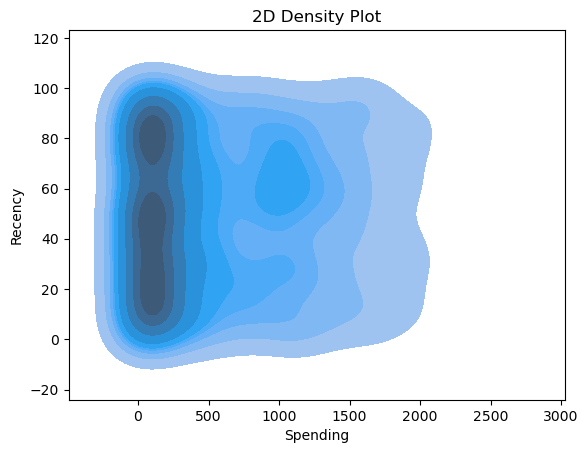

In [54]:
# let´s see graphically how data is distributed

sns.kdeplot(x=df['Spending'], y=df['Recency'], fill=True)
plt.title('2D Density Plot')
plt.show()

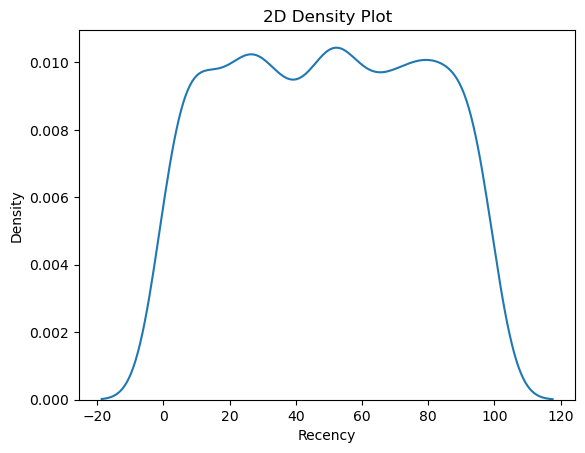

In [359]:
sns.kdeplot(x=df['Recency'])
plt.title('2D Density Plot')
plt.show()

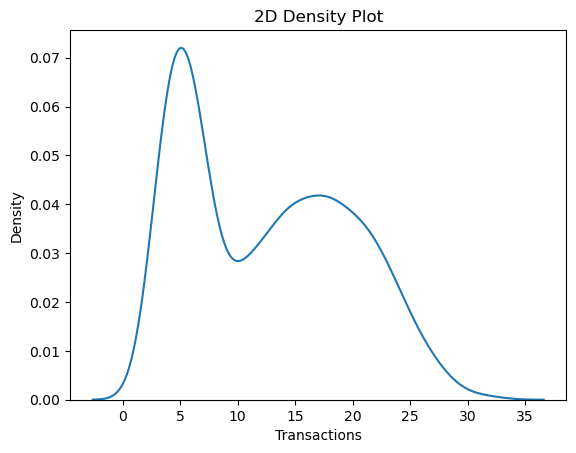

In [363]:
sns.kdeplot(x=df['Transactions'])
plt.title('2D Density Plot')
plt.show()

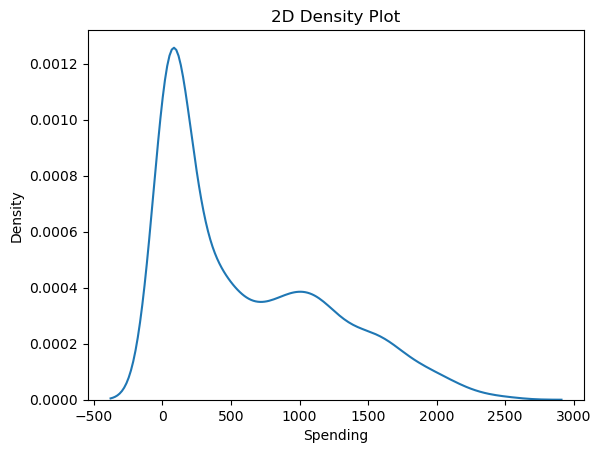

In [365]:
sns.kdeplot(x=df['Spending'])
plt.title('2D Density Plot')
plt.show()

## Now let´s see how many groups do we need

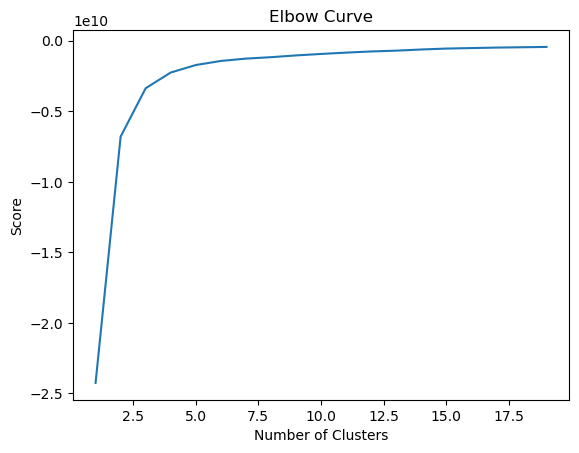

In [59]:
# get right number of cluster for K-means so we neeed to loop from 1 to 20 number of cluster and check score.
#Elbow method is used to represnt that. 
Nc = range(1, 20)
kmeans = [KMeans(n_clusters=i) for i in Nc]
score = [kmeans[i].fit(RFM).score(RFM) for i in range(len(kmeans))]
plt.plot(Nc,score)
plt.xlabel('Number of Clusters')
plt.ylabel('Score')
plt.title('Elbow Curve')
plt.show()



In [61]:
RFM.set_index('ID',inplace=True) # quitamos el cliente como variable

In [63]:
# we can take 3-4 clusters. let´s now ufit the data

kmeans =  KMeans(n_clusters=3, random_state=0)
# Kmeans =  KMedoids(n_clusters=3, random_state=0) -> intentaremos mas adelante usar este metodo



kmeans.fit(RFM)
RFM['Cluster'] = kmeans.labels_
RFM.head()



,Spending,Transactions,Recency,Cluster
ID,,,,
5524,1617,22,58,2
2174,27,4,38,0
4141,776,20,26,1
6182,53,6,26,0
5324,422,14,94,0


In [65]:
kmeans.cluster_centers_

array([[ 153.46111111,    7.31190476,   48.7015873 ],
       [ 920.14003295,   19.12191104,   48.8616145 ],
       [1670.02216066,   20.10249307,   50.81440443]])

<Axes: xlabel='Cluster', ylabel='Recency'>

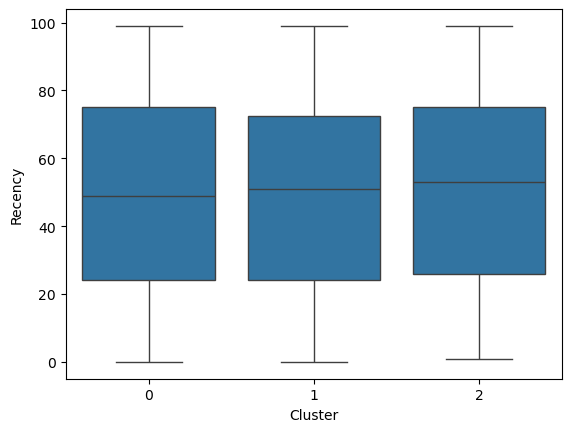

In [67]:
# now let´s understand the segments
sns.boxplot(x=RFM.Cluster, y=RFM.Recency)

<Axes: xlabel='Cluster', ylabel='Spending'>

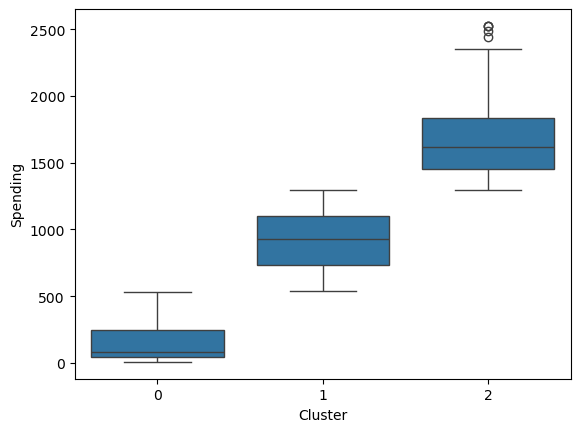

In [69]:
sns.boxplot(x=RFM.Cluster, y=RFM.Spending)

<Axes: xlabel='Cluster', ylabel='Transactions'>

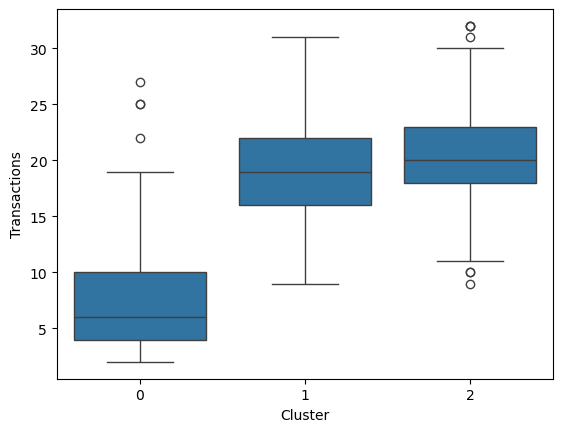

In [71]:
sns.boxplot(x=RFM.Cluster, y=RFM.Transactions)

In [95]:
#Make sure your data is numerical and scaled, especially if the variables are on different scales. Use StandardScaler if needed.
#Unlike KMedoids, KMeans is sensitive to outliers and assumes spherical clusters.

#RFM.set_index('ID',inplace=True) # quitamos el cliente como variable
scaler = StandardScaler()
RFM_scaled = scaler.fit_transform(RFM)

kmeans =  KMeans(n_clusters=5, random_state=0)

kmeans.fit(RFM_scaled)
RFM['Cluster'] = kmeans.labels_
RFM.head()

ValueError: could not convert string to float: 'bronce'

segmentamos mejor con 5 clusters¿


<Axes: xlabel='Cluster', ylabel='Recency'>

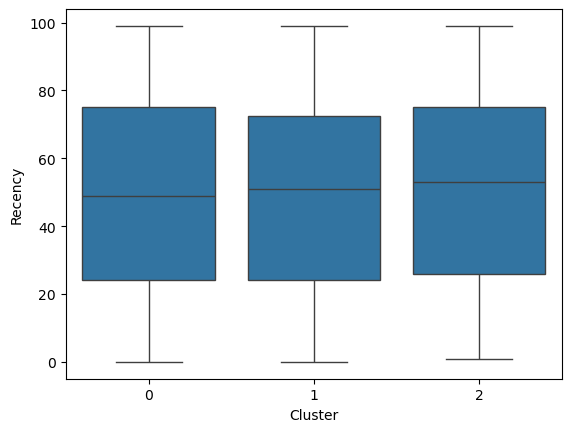

In [77]:
# now let´s understand the segments
sns.boxplot(x=RFM.Cluster, y=RFM.Recency)

<Axes: xlabel='Cluster', ylabel='Spending'>

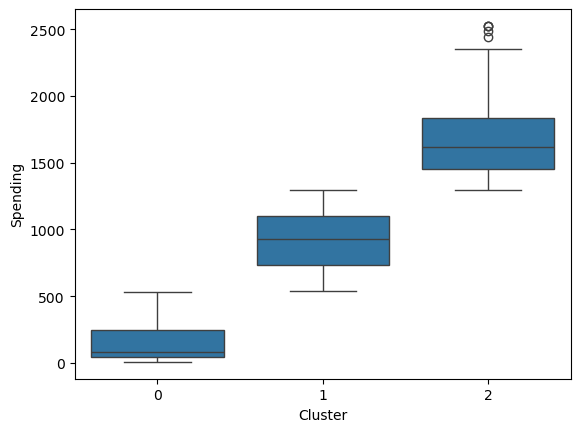

In [79]:
sns.boxplot(x=RFM.Cluster, y=RFM.Spending)

<Axes: xlabel='Cluster', ylabel='Transactions'>

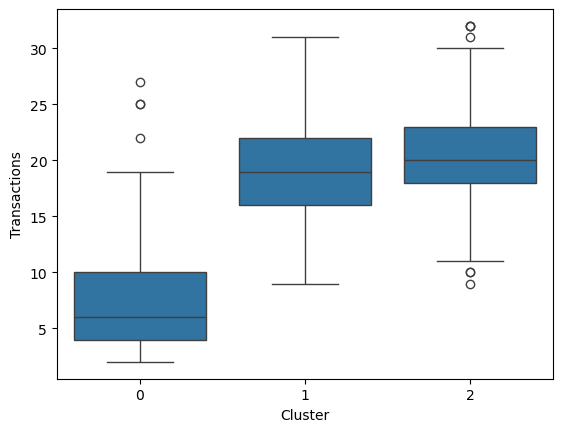

In [81]:
sns.boxplot(x=RFM.Cluster, y=RFM.Transactions)

In [83]:
#let´s rename clusters

segt_map = {
    0: 'Silver',
    1: 'Bronce',
    2: 'Gold',
    #3: 'broncee - at risk',
    #4: 'gold',
 
}

RFM['Cluster_2'] = RFM['Cluster'].map(str)
RFM['Segment'] = RFM['Cluster'].replace(segt_map, regex=True)
RFM.head()

,Spending,Transactions,Recency,Cluster,Cluster_2,Segment
ID,,,,,,
5524,1617,22,58,2,2,bronce
2174,27,4,38,0,0,silver - at risk
4141,776,20,26,1,1,gold - at risk
6182,53,6,26,0,0,silver - at risk
5324,422,14,94,0,0,silver - at risk


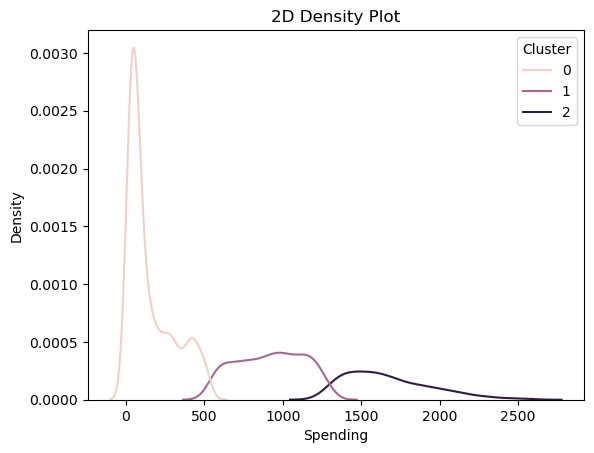

In [85]:
sns.kdeplot(data=RFM, x='Spending', hue='Cluster')  # Pass RFM as the data parameter
plt.title('2D Density Plot')
plt.show()

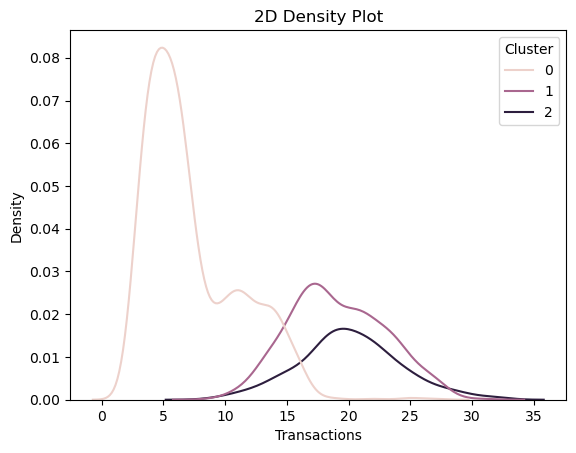

In [87]:
sns.kdeplot(data=RFM, x='Transactions', hue='Cluster')  # Pass RFM as the data parameter
plt.title('2D Density Plot')
plt.show()

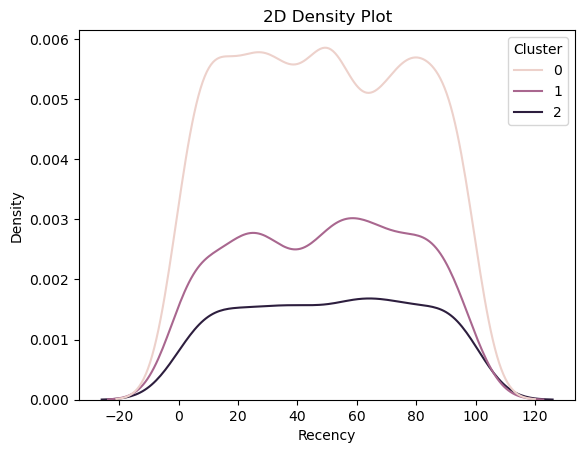

In [89]:
sns.kdeplot(data=RFM, x='Recency', hue='Cluster')  # Pass RFM as the data parameter
plt.title('2D Density Plot')
plt.show()

## 4. Let´s start de CLV calculation
we will use the especialized library for CLV calculations called LIFETIMES


In [103]:
#we add date last transfer
RFM=RFM.merge(df[['ID','Dt_Customer']], on='ID')

In [137]:
#we define the date of study
#studydate_date = date(2014,10, 4)
# make difference between date of entrance and date of study


In [316]:
#We’ll use the BG/NBD model first ->BetaGeoFitter that needs Transactions, recency, and frencuency. we need to calculate the lastest

RFM['T']=(pd.to_datetime('2014-10-04 0:00:00')-pd.to_datetime(RFM['Dt_Customer'])).dt.days
#RFM['T']= RFM['T'].astype('int64')

# following the definitions of lifetimes
RFM['Spending_C']=RFM['Spending']/RFM['Transactions']
RFM['Transactions_C']=RFM['Transactions']-1
RFM['Recency2']=(RFM['T']-RFM['Recency'])

In [324]:
RFM

,ID,Spending,Transactions,Recency,Cluster,Cluster_2,Segment,Dt_Customer,TEST,T,Spending_C,Transactions_C,Predicted_purchases,p_alive,Predicted_profit,LTV,Recency2
0,5524,1617,22,58,2,2,bronce,2012-09-04,760 days,760,73.500000,21,1.819712e-23,1.150591e-23,53.345995,1.930126e-22,702
1,2174,27,4,38,0,0,silver - at risk,2014-03-08,210 days,210,6.750000,3,2.415039e-02,2.513043e-02,46.958568,2.221708e-01,172
2,4141,776,20,26,1,1,gold - at risk,2013-08-21,409 days,409,38.800000,19,1.829151e-22,7.212906e-23,46.628384,1.763736e-21,383
3,6182,53,6,26,0,0,silver - at risk,2014-02-10,236 days,236,8.833333,5,7.666928e-05,5.826544e-05,46.182039,7.019562e-04,210
4,5324,422,14,94,0,0,silver - at risk,2014-01-19,258 days,258,30.142857,13,3.622204e-05,1.320900e-05,45.960267,3.484295e-04,164
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2223,10870,1341,16,46,2,2,bronce,2013-06-13,478 days,478,83.812500,15,3.712263e-15,2.072287e-15,53.683139,4.001980e-14,432
2224,4001,444,15,56,0,0,silver - at risk,2014-06-10,116 days,116,29.600000,14,1.643373e-03,2.997136e-04,45.724075,1.803502e-02,60
2225,7270,1241,18,91,1,1,gold - at risk,2014-01-25,252 days,252,68.944444,17,7.165182e-07,2.050469e-07,51.798588,8.015291e-06,161
2226,8235,843,21,8,1,1,gold - at risk,2014-01-24,253 days,253,40.142857,20,3.787562e-29,9.538313e-30,46.809360,3.908201e-28,245


In [318]:

#let´s fit the model
bgf = BetaGeoFitter(penalizer_coef=0.000000005)
bgf.fit(RFM['Transactions_C'], RFM['Recency2'], RFM['T'])
bgf.summary



,coef,se(coef),lower 95% bound,upper 95% bound
r,1.417456,0.047282,1.324782,1.510130
alpha,39.745628,1.659255,36.493489,42.997768
a,4.703731,1.370331,2.017881,7.389580
b,441.315362,123.459804,199.334146,683.296577


<Axes: title={'center': 'Frequency of Repeat Transactions'}, xlabel='Number of Calibration Period Transactions', ylabel='Customers'>

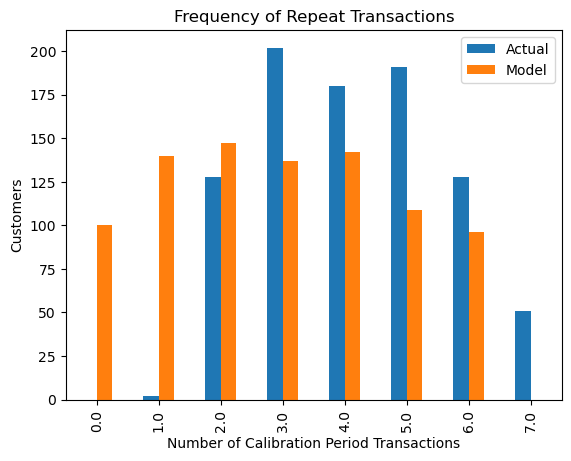

In [320]:
#now let´s check the results
plot_period_transactions(bgf)

# we see model is not fitting well the data

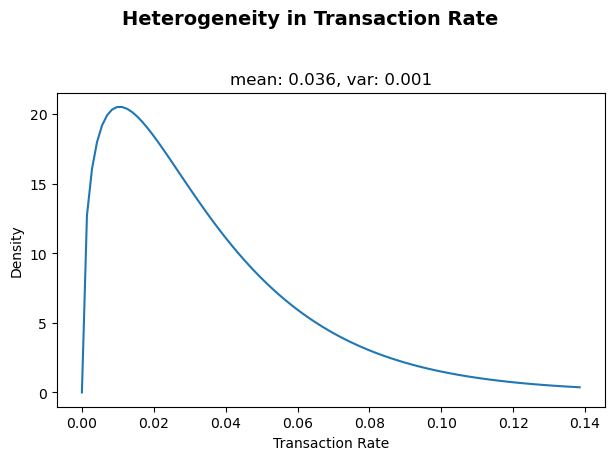

In [322]:
# plot the estimated gamma distribution of λ (customers' propensities to purchase)
plot_transaction_rate_heterogeneity(bgf);

<Axes: title={'center': 'Expected Number of Future Purchases for 1 Unit of Time,\nby Frequency and Recency of a Customer'}, xlabel="Customer's Historical Frequency", ylabel="Customer's Recency">

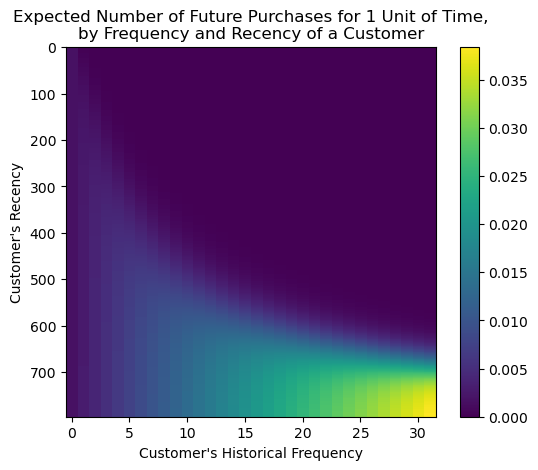

In [326]:
plot_frequency_recency_matrix(bgf)

Customers with higher number of purchases and for a longer time span are more likely to purchase. There is a tail where customers with less purchases but smaller recencies are still likely to purchase


<Axes: title={'center': 'Probability Customer is Alive,\nby Frequency and Recency of a Customer'}, xlabel="Customer's Historical Frequency", ylabel="Customer's Recency">

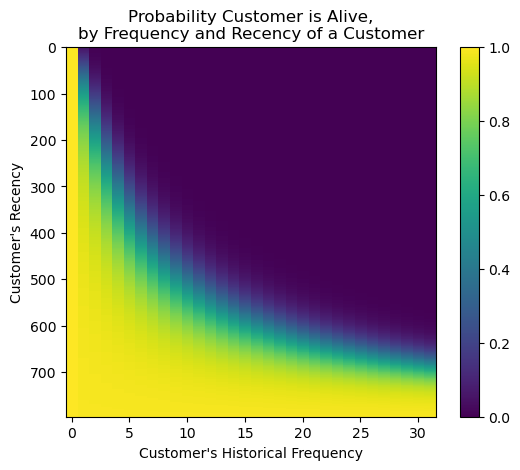

In [328]:
plot_probability_alive_matrix(bgf)

- Here the probability of being alive i high when there is a large number of purchases and long recency.
- When a customers has a small number of transactions but the recency is low, there is also high probability of still being alive(top left)

In [330]:
t = 60 # This is the horizon
RFM['Predicted_purchases'] = bgf.conditional_expected_number_of_purchases_up_to_time(t, RFM['Transactions_C'], RFM['Recency'], RFM['T'])
RFM['p_alive']             = bgf.conditional_probability_alive(RFM['Transactions_C'], RFM['Recency'], RFM['T'])

In [332]:
RFM.sort_values(by='Predicted_purchases').tail(5)

,ID,Spending,Transactions,Recency,Cluster,Cluster_2,Segment,Dt_Customer,TEST,T,Spending_C,Transactions_C,Predicted_purchases,p_alive,Predicted_profit,LTV,Recency2
1804,8093,914,13,72,1,1,gold - at risk,2014-06-28,98 days,98,70.307692,12,4.829610,0.853123,51.084500,13.009581,26
44,1371,984,15,72,1,1,gold - at risk,2014-06-28,98 days,98,65.600000,14,5.139096,0.793369,50.807520,8.854646,26
1479,2939,1631,14,96,2,2,bronce,2014-06-22,104 days,104,116.500000,13,5.690147,0.976857,57.398840,61.620165,8
792,6722,767,20,98,1,1,gold - at risk,2014-06-28,98 days,98,38.350000,19,8.403989,0.989863,46.546287,86.127258,0
1792,2831,1179,24,99,1,1,gold - at risk,2014-06-27,99 days,99,49.125000,23,9.902509,0.989950,48.534721,105.311120,0


We want to estiamte the profit, but for this we need GammaGammaFitter.

The Gamma-Gamma model and the independence assumption:
The model we are going to use to estimate the CLV for our userbase is called the Gamma-Gamma submodel, which relies upon an important assumption. 
The Gamma-Gamma submodel, in fact, assumes that there is no relationship between the monetary value and the purchase frequency. 
In practice we need to check whether the Pearson correlation between the two vectors is close to 0 in order to use this model.


In [335]:
RFM[['Spending_C', 'Transactions_C']].corr()

,Spending_C,Transactions_C
Spending_C,1.000000,0.643656
Transactions_C,0.643656,1.000000


In [337]:
# We fit the Gamma-Gamma model to our data
ggf = GammaGammaFitter(penalizer_coef = 0)
ggf.fit(RFM['Transactions_C'],RFM['Spending_C'])
print(ggf)


<lifetimes.GammaGammaFitter: fitted with 2228 subjects, p: 0.28, q: 25.08, v: 4118.93>


In [339]:
#The Gamma-Gamma model and the independence assumption
#The model we are going to use to estimate the CLV for our userbase is called the Gamma-Gamma submodel, which relies upon an important assumption. 
#The Gamma-Gamma submodel, in fact, assumes that there is no relationship between the monetary value and the purchase frequency. 
#In practice we need to check whether the Pearson correlation between the two vectors is close to 0 in order to use this model.

RFM['Predicted_profit']    = ggf.conditional_expected_average_profit(RFM['Transactions_C'], RFM['Spending_C'])
RFM.head()

,ID,Spending,Transactions,Recency,Cluster,Cluster_2,Segment,Dt_Customer,TEST,T,Spending_C,Transactions_C,Predicted_purchases,p_alive,Predicted_profit,LTV,Recency2
0,5524,1617,22,58,2,2,bronce,2012-09-04,760 days,760,73.500000,21,5.618677e-19,3.370383e-19,53.345995,1.930126e-22,702
1,2174,27,4,38,0,0,silver - at risk,2014-03-08,210 days,210,6.750000,3,3.712798e-01,3.522307e-01,46.958568,2.221708e-01,172
2,4141,776,20,26,1,1,gold - at risk,2013-08-21,409 days,409,38.800000,19,2.447268e-15,9.094683e-16,46.628384,1.763736e-21,383
3,6182,53,6,26,0,0,silver - at risk,2014-02-10,236 days,236,8.833333,5,1.311234e-02,9.469284e-03,46.182039,7.019562e-04,210
4,5324,422,14,94,0,0,silver - at risk,2014-01-19,258 days,258,30.142857,13,2.684454e-03,9.387189e-04,45.960267,3.484295e-04,164


In [341]:
print(f"Expected Average sales: {RFM['Predicted_profit'].mean()}")
print(f"Actual Average sales: {RFM['Spending_C'].mean()}")

Expected Average sales: 48.374416115770465
Actual Average sales: 37.329357186064286


In [355]:
# FInalluy we estimate the customer lifetime value

RFM['LTV']= ggf.customer_lifetime_value(
    bgf, #the model to use to predict the number of future transactions
    RFM['Transactions_C'],
    RFM['Recency2'],
    RFM['T'],
    RFM['Spending_C'],
    time=12, # months,
    freq='D',
    discount_rate=0.01 # monthly discount rate ~ 12.7% annually
)
RFM

,ID,Spending,Transactions,Recency,Cluster,Cluster_2,Segment,Dt_Customer,TEST,T,Spending_C,Transactions_C,Predicted_purchases,p_alive,Predicted_profit,LTV,Recency2
0,5524,1617,22,58,2,2,bronce,2012-09-04,760 days,760,73.500000,21,5.618677e-19,3.370383e-19,53.345995,454.675432,702
1,2174,27,4,38,0,0,silver - at risk,2014-03-08,210 days,210,6.750000,3,3.712798e-01,3.522307e-01,46.958568,263.822684,172
2,4141,776,20,26,1,1,gold - at risk,2013-08-21,409 days,409,38.800000,19,2.447268e-15,9.094683e-16,46.628384,637.398593,383
3,6182,53,6,26,0,0,silver - at risk,2014-02-10,236 days,236,8.833333,5,1.311234e-02,9.469284e-03,46.182039,338.971092,210
4,5324,422,14,94,0,0,silver - at risk,2014-01-19,258 days,258,30.142857,13,2.684454e-03,9.387189e-04,45.960267,198.223668,164
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2223,10870,1341,16,46,2,2,bronce,2013-06-13,478 days,478,83.812500,15,2.756070e-11,1.463543e-11,53.683139,517.087197,432
2224,4001,444,15,56,0,0,silver - at risk,2014-06-10,116 days,116,29.600000,14,2.914336e-01,5.066119e-02,45.724075,116.593785,60
2225,7270,1241,18,91,1,1,gold - at risk,2014-01-25,252 days,252,68.944444,17,1.372402e-04,3.697025e-05,51.798588,89.058347,161
2226,8235,843,21,8,1,1,gold - at risk,2014-01-24,253 days,253,40.142857,20,5.696230e-15,1.327852e-15,46.809360,996.721107,245


In [351]:
RFM.describe()

,ID,Spending,Transactions,Recency,Cluster,TEST,T,Spending_C,Transactions_C,Predicted_purchases,p_alive,Predicted_profit,LTV,Recency2
count,2228.000000,2228.000000,2228.000000,2228.000000,2228.000000,2228,2228.000000,2228.000000,2228.000000,2.228000e+03,2.228000e+03,2228.000000,2.228000e+03,2228.000000
mean,5582.301167,608.062837,12.601885,49.087522,0.596499,450 days 20:02:48.043087968,450.835278,37.329357,11.601885,1.319325e-01,7.746166e-02,48.374416,3.261834e+01,401.747756
std,3244.783992,602.154979,7.170509,28.987571,0.751664,201 days 21:22:14.191260680,201.890442,29.836214,7.170509,5.089776e-01,2.022337e-01,3.439048,1.217140e+02,203.275155
min,0.000000,8.000000,2.000000,0.000000,0.000000,97 days 00:00:00,97.000000,2.666667,1.000000,6.533115e-36,2.024239e-36,39.458873,1.626622e-33,0.000000
25%,2814.750000,69.000000,6.000000,24.000000,0.000000,278 days 00:00:00,278.000000,13.000000,5.000000,7.392140e-13,4.060805e-13,46.338083,2.072204e-10,227.000000
50%,5447.000000,399.000000,12.000000,49.000000,0.000000,453 days 00:00:00,453.000000,29.642857,11.000000,1.426573e-06,8.959667e-07,46.906071,3.752516e-04,402.000000
75%,8416.500000,1048.000000,18.000000,74.000000,1.000000,626 days 00:00:00,626.000000,49.068750,17.000000,1.020280e-02,1.102453e-02,48.507455,2.623617e+00,575.250000
max,11191.000000,2525.000000,32.000000,99.000000,2.000000,796 days 00:00:00,796.000000,187.666667,31.000000,9.902509e+00,9.899497e-01,64.311612,2.132098e+03,791.000000


In [357]:
#FInally let´s see how this is reflecting by groups
RFM.groupby('Segment')['LTV'].mean()
#silver is performing better?

Segment
bronce              534.550775
gold - at risk      500.198682
silver - at risk    263.088278
Name: LTV, dtype: float64